# Inverse-ablation evaluation on the experimental test set

Evaluate the unique-configuration learning curves and experimental/synthetic data splits using Hungarian point-matching F1 with a 4-pixel tolerance. Every checkpoint uses the established matched test set: 96 random-condition plus 36 fixed-condition patterns (132 total).

In [13]:
import sys as _path_sys
from pathlib import Path as _Path
_PAPER_ROOT = next(p for p in (_Path.cwd(), *_Path.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_PAPER_ROOT) not in _path_sys.path: _path_sys.path.insert(0, str(_PAPER_ROOT))
import json
import os
from pathlib import Path
import pandas as pd
import torch
from IPython.display import Image, display

# Support launching here or from the repository root.
if not Path("inverse_evaluation.py").is_file():
    notebook_dir = Path.cwd() / "information_encoding_decoding"
    if notebook_dir.is_dir():
        os.chdir(notebook_dir)

import inverse_evaluation as pipeline
pipeline.OUTPUT_DIR = Path(__import__('paper_paths').inverse_results('inverse_ablation_evaluation_real_test_4gpu_lr5e4_best'))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"Output: {pipeline.OUTPUT_DIR.resolve()}")

Device: cuda
Output: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/information_encoding_decoding/inverse_ablation_evaluation_real_test_4gpu_lr5e4_best


## Audit the test pairs and review the checkpoints

Synthetic N30000 and the 0% experimental endpoint share the best-validation-loss checkpoint of the completed 4-GPU, LR=5e-4 baseline (job 60235784). Other conditions retain `last.ckpt` and their 1-GPU, LR=1e-4 training setup, so this comparison also varies training settings. For mixture retries, the most recently updated `last.ckpt` across the original and retry directories is selected.

In [8]:
datasets = pipeline.make_test_datasets()
test_inventory = pipeline.audit_test_set(datasets)
from utils.config import SIMULATION_CONDITIONED_LR5E4_RUN_DIR, CKPT_PATH_SIMULATION_CONDITIONED_LR5E4_BEST

runs = [dict(run) for run in pipeline.UNIQUE_CONFIGURATION_RUNS + pipeline.MIXTURE_RUNS]
for run in runs:
    if ((run['family'] == 'synthetic' and run['condition'] == 'N30000')
            or (run['comparison'] == 'mixture' and run['x'] == 0)):
        run['root'] = SIMULATION_CONDITIONED_LR5E4_RUN_DIR
        run['label'] += ' (4 GPUs, LR=5e-4)'
selected = [(run, Path(CKPT_PATH_SIMULATION_CONDITIONED_LR5E4_BEST)
             if run['root'] == SIMULATION_CONDITIONED_LR5E4_RUN_DIR
             else pipeline.find_last_checkpoint(run)) for run in runs]
display(pd.DataFrame(test_inventory))
display(pd.DataFrame([{
    "comparison": run["comparison"], "family": run["family"],
    "condition": run["condition"], "x": run["x"],
    "checkpoint_selection": checkpoint.name,
    "checkpoint": str(checkpoint),
} for run, checkpoint in selected]))

,subset,n_images
0,random,96
1,fixed,36


,comparison,family,condition,x,checkpoint_selection,checkpoint
0,unique_configuration,experimental,N10,10,last.ckpt,/hpc/dctrl/ks723/Physics_constrained_DL_patter...
1,unique_configuration,experimental,N50,50,last.ckpt,/hpc/dctrl/ks723/Physics_constrained_DL_patter...
2,unique_configuration,experimental,N100,100,last.ckpt,/hpc/dctrl/ks723/Physics_constrained_DL_patter...
3,unique_configuration,experimental,NMAX,195,last.ckpt,/hpc/dctrl/ks723/Physics_constrained_DL_patter...
4,unique_configuration,synthetic,N10,10,last.ckpt,/hpc/dctrl/ks723/Physics_constrained_DL_patter...
5,unique_configuration,synthetic,N50,50,last.ckpt,/hpc/dctrl/ks723/Physics_constrained_DL_patter...
6,unique_configuration,synthetic,N100,100,last.ckpt,/hpc/dctrl/ks723/Physics_constrained_DL_patter...
7,unique_configuration,synthetic,N500,500,last.ckpt,/hpc/dctrl/ks723/Physics_constrained_DL_patter...
8,unique_configuration,synthetic,N1000,1000,last.ckpt,/hpc/dctrl/ks723/Physics_constrained_DL_patter...
9,unique_configuration,synthetic,N5000,5000,last.ckpt,/hpc/dctrl/ks723/Physics_constrained_DL_patter...


## Freeze the selected checkpoints

Hard links make this run reproducible without duplicating checkpoint storage. This cell refuses to overwrite an existing output directory; change `pipeline.OUTPUT_DIR` above for another run.

In [9]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
pipeline.OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
checkpoints = pipeline.snapshot_checkpoints(selected)
settings = {
    "device": str(device),
    "prediction_threshold": pipeline.PREDICTION_THRESHOLD,
    "matching_algorithm": "hungarian",
    "matching_tolerance_pixels": pipeline.MATCHING_TOLERANCE,
    "checkpoint_selection": "best validation loss for synthetic N30000 and 0% experimental; last.ckpt for other conditions",
    "test_set": test_inventory,
    "number_test_images": sum(row["n_images"] for row in test_inventory),
    "uncertainty_in_plots": "95% normal CI of per-image mean (1.96 * SEM)",
    "runs": [{
        "comparison": run["comparison"], "family": run["family"],
        "condition": run["condition"], "x": run["x"],
        "source_checkpoint": str(source.resolve()),
        "checkpoint_selection": source.name,
        "snapshot_checkpoint": str(snapshot.resolve()),
    } for (run, source), (_, snapshot) in zip(selected, checkpoints)],
}
with (_figure_source_path(pipeline.OUTPUT_DIR / "evaluation_settings.json")).open("w") as handle:
    json.dump(settings, handle, indent=2)
print(f"Frozen {len(set(path for _, path in checkpoints))} unique checkpoints")

Frozen 15 unique checkpoints


## Run inference

This is the long-running cell. It saves the accumulated per-image and summary CSV files after every completed graph entry.

In [10]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
all_rows, summaries = [], []
for run, checkpoint in checkpoints:
    rows = pipeline.evaluate_run(run, checkpoint, datasets, device)
    all_rows.extend(rows)
    summaries.extend(pipeline.summarize(run, checkpoint, rows, subset)
                     for subset in ("all", "random", "fixed"))
    for summary_row in summaries[-3:]:
        summary_row['checkpoint_selection'] = 'best validation loss' if 'best-' in checkpoint.name else 'last.ckpt'
    pipeline.write_csv(_figure_source_path(pipeline.OUTPUT_DIR / "per_image_metrics.csv"), all_rows)
    pipeline.write_csv(_figure_source_path(pipeline.OUTPUT_DIR / "summary_metrics.csv"), summaries)
print(f"Completed {len(checkpoints)} graph entries")

Evaluating Experimental N10: inverse_ablation_evaluation_real_test_4gpu_lr5e4_best/checkpoint_snapshot/00_experimental_N10_seed42_last.ckpt
Evaluating Experimental N50: inverse_ablation_evaluation_real_test_4gpu_lr5e4_best/checkpoint_snapshot/01_experimental_N50_seed42_last.ckpt
Evaluating Experimental N100: inverse_ablation_evaluation_real_test_4gpu_lr5e4_best/checkpoint_snapshot/02_experimental_N100_seed42_last.ckpt
Evaluating Experimental NMAX (195): inverse_ablation_evaluation_real_test_4gpu_lr5e4_best/checkpoint_snapshot/03_experimental_NMAX_seed42_last.ckpt
Evaluating Synthetic N10: inverse_ablation_evaluation_real_test_4gpu_lr5e4_best/checkpoint_snapshot/04_synthetic_N10_seed42_last.ckpt
Evaluating Synthetic N50: inverse_ablation_evaluation_real_test_4gpu_lr5e4_best/checkpoint_snapshot/05_synthetic_N50_seed42_last.ckpt
Evaluating Synthetic N100: inverse_ablation_evaluation_real_test_4gpu_lr5e4_best/checkpoint_snapshot/06_synthetic_N100_seed42_last.ckpt
Evaluating Synthetic N500:

## Results and plots

The main results use all 132 patterns. Plot error bars are 95% normal confidence intervals of the per-image mean. PNG and vector PDF copies are saved.

,comparison,family,condition,x,n_images,tolerance_precision_mean,tolerance_recall_mean,tolerance_f1_mean,tolerance_f1_std
0,unique_configuration,experimental,N10,10,132,0.682927,0.238330,0.318344,0.262095
3,unique_configuration,experimental,N50,50,132,0.845925,0.604525,0.676950,0.230661
6,unique_configuration,experimental,N100,100,132,0.864841,0.749445,0.778869,0.183365
9,unique_configuration,experimental,NMAX,195,132,0.817899,0.795471,0.788919,0.187208
12,unique_configuration,synthetic,N10,10,132,0.729399,0.532749,0.570328,0.203143
15,unique_configuration,synthetic,N50,50,132,0.844695,0.572129,0.645852,0.197195
18,unique_configuration,synthetic,N100,100,132,0.841720,0.723755,0.751035,0.187799
21,unique_configuration,synthetic,N500,500,132,0.798768,0.698282,0.709419,0.231661
24,unique_configuration,synthetic,N1000,1000,132,0.816784,0.717894,0.731612,0.218793
27,unique_configuration,synthetic,N5000,5000,132,0.832764,0.683516,0.715817,0.189431


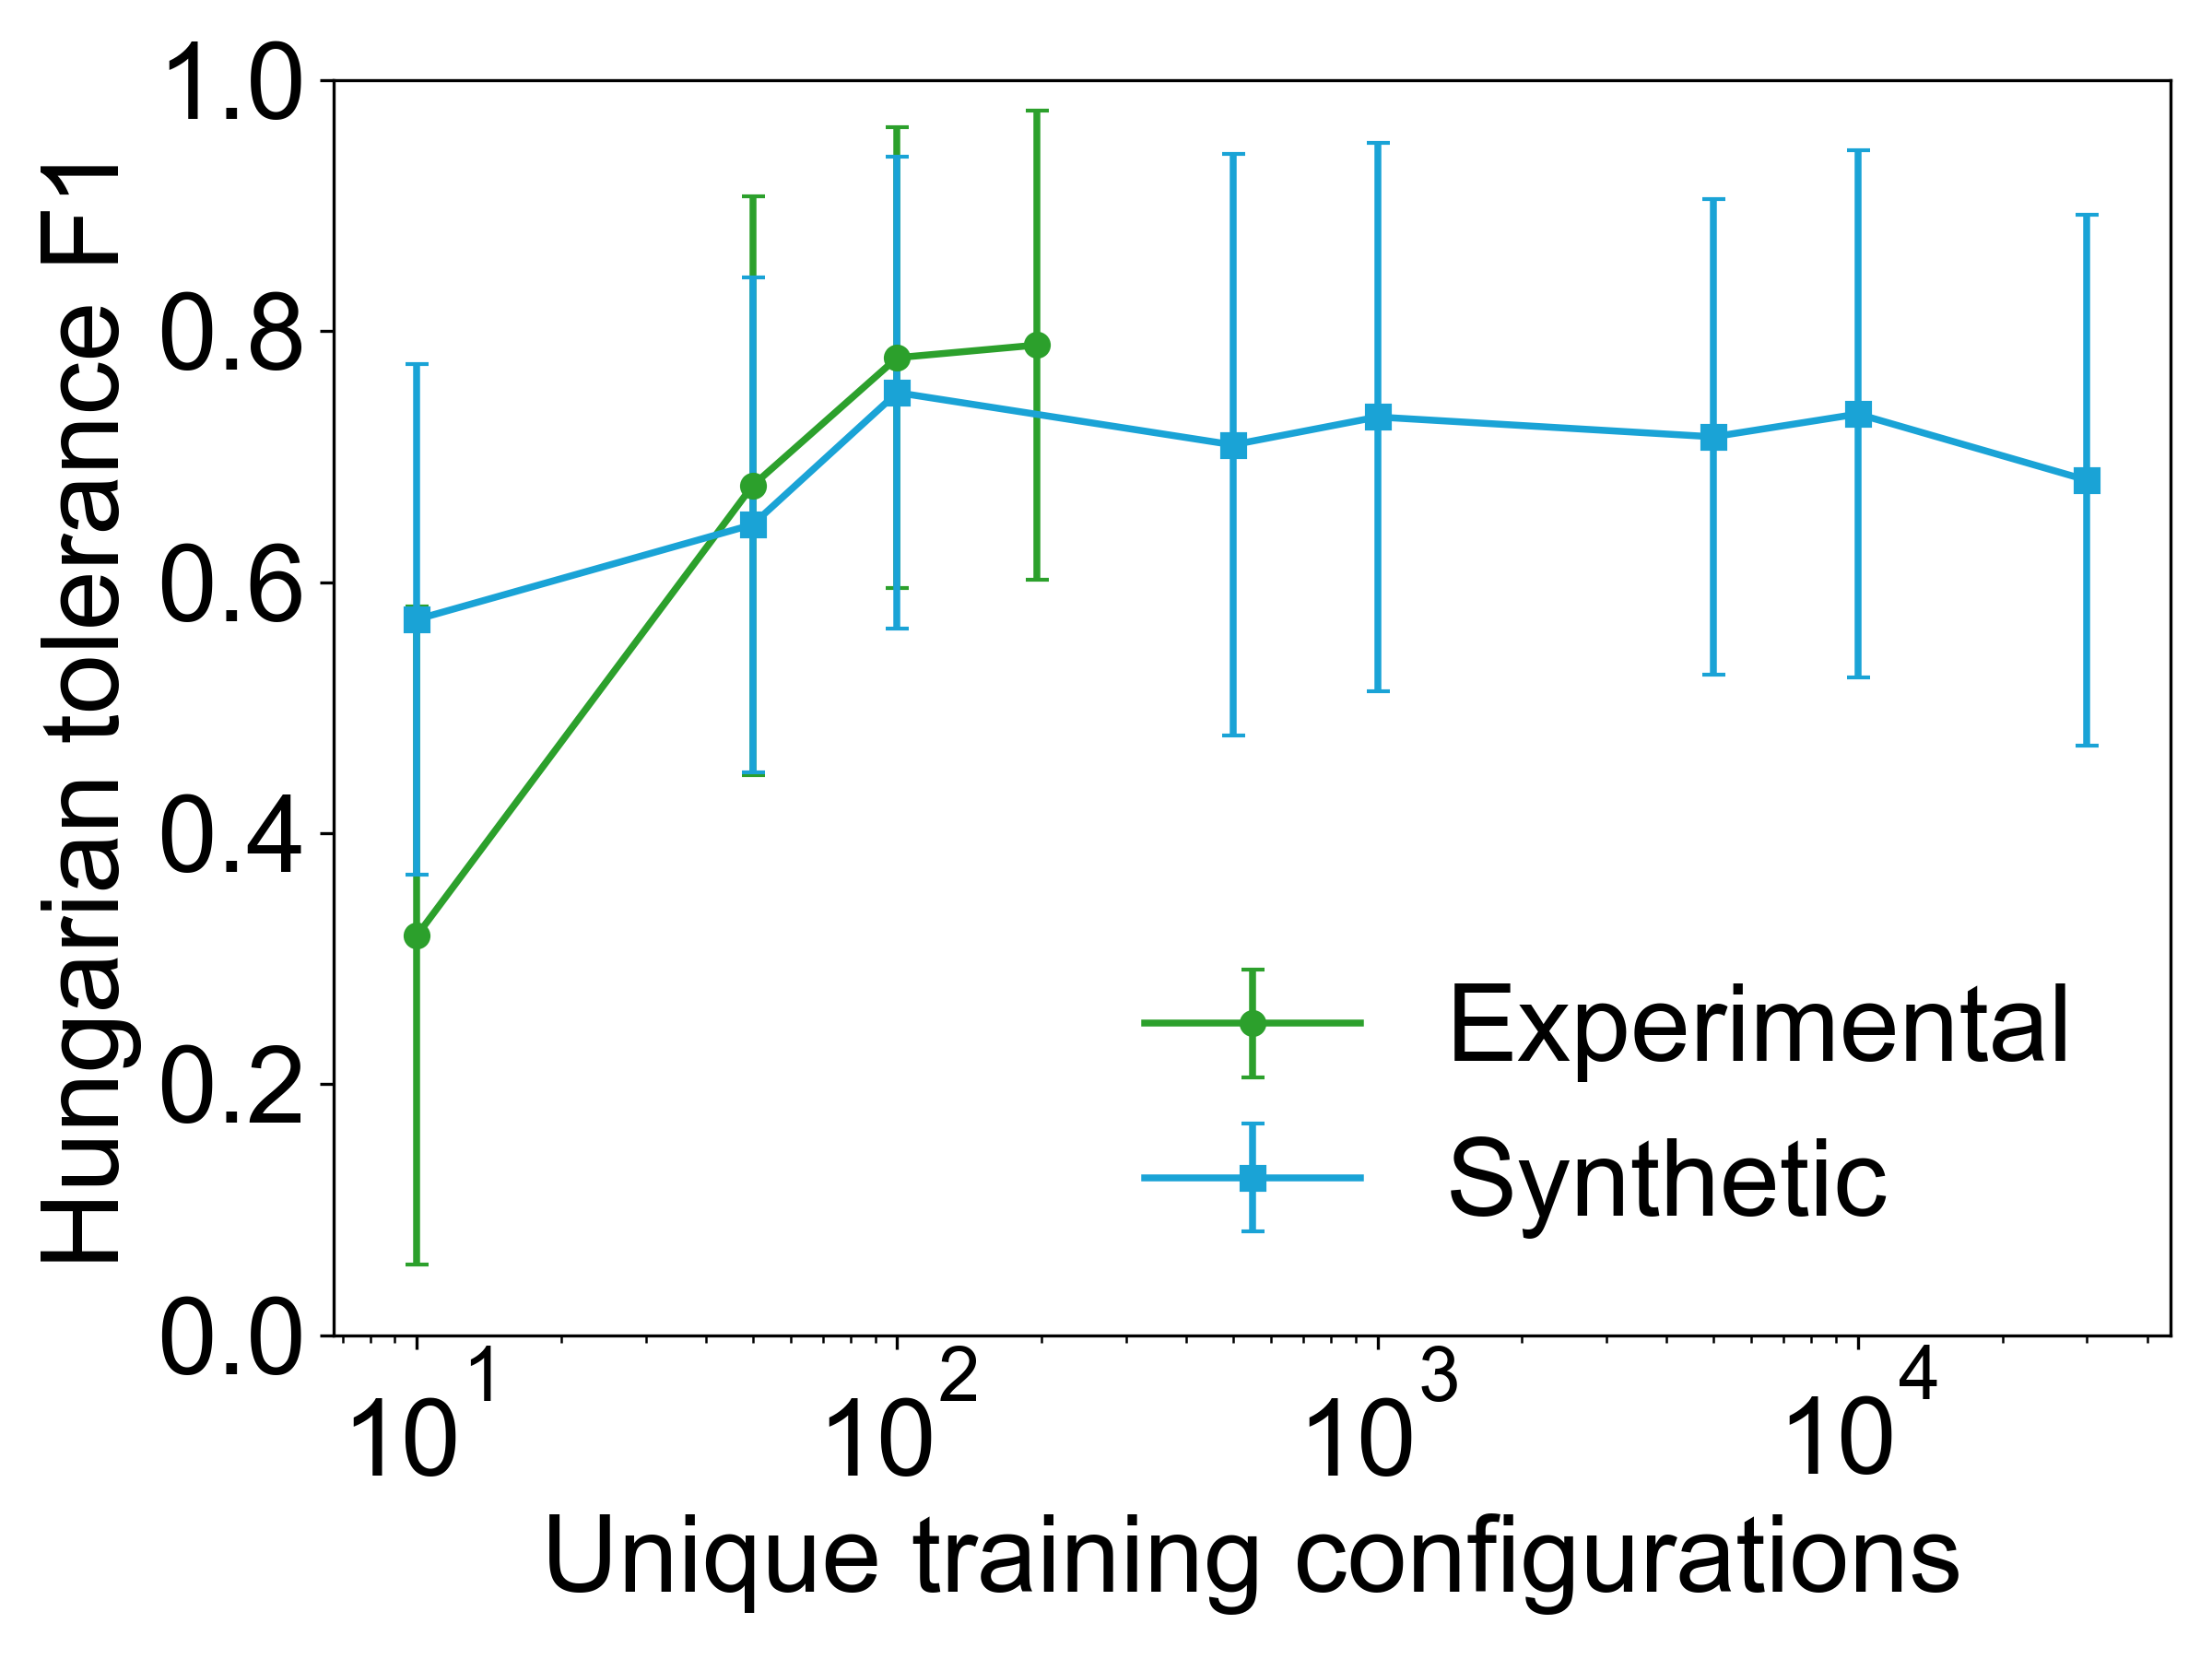

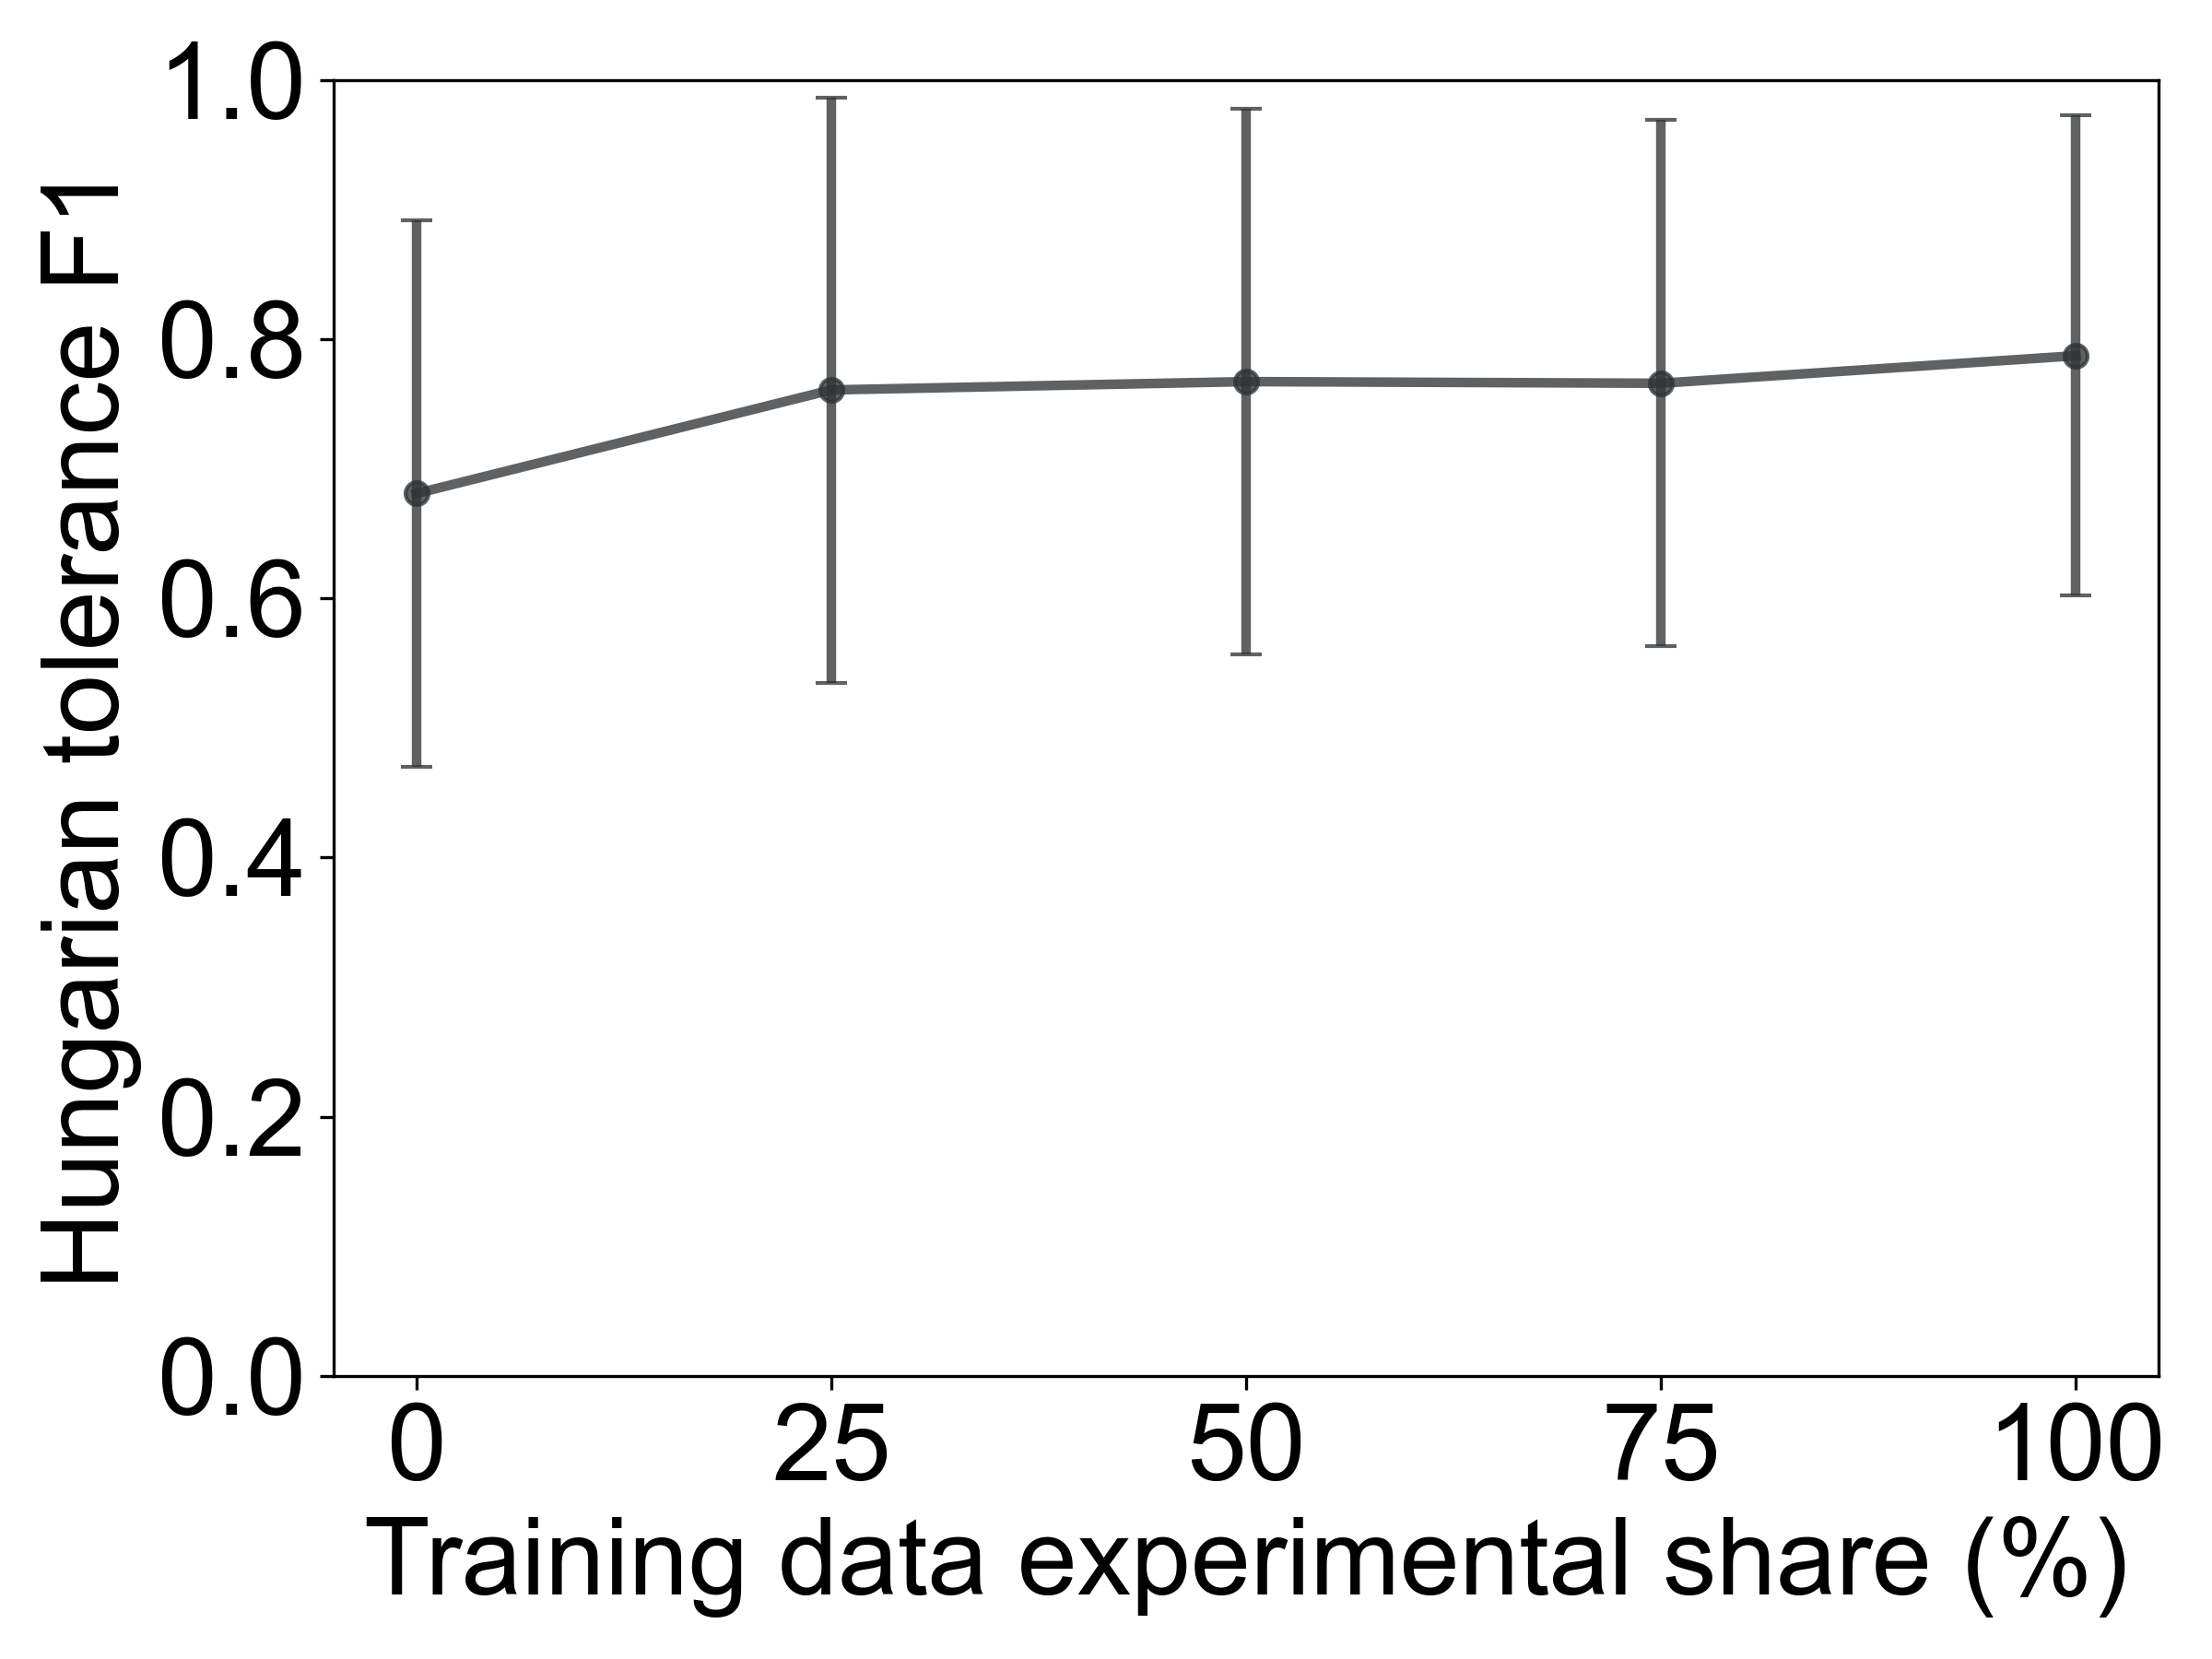

In [14]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
summary = pd.read_csv(_figure_source_path(pipeline.OUTPUT_DIR / "summary_metrics.csv"))
columns = ["comparison", "family", "condition", "x", "n_images",
           "tolerance_precision_mean", "tolerance_recall_mean",
           "tolerance_f1_mean", "tolerance_f1_std"]
display(summary.loc[summary["subset"] == "all", columns])
from matplotlib import font_manager as fm
import matplotlib.pyplot as plt
from utils.config import FPATH

fm.fontManager.addfont(str(FPATH))
UNIQUE_CURVE_FONT_FAMILY = fm.FontProperties(fname=str(FPATH)).get_name()
UNIQUE_CURVE_LABEL_FONTSIZE = 28
UNIQUE_CURVE_TICK_FONTSIZE = 28
UNIQUE_CURVE_LEGEND_FONTSIZE = 28

def plot_unique_configuration_curve_notebook(summaries):
    figure, axis = plt.subplots(figsize=(8, 6))
    styles = {"experimental": ("o", "tab:green"), "synthetic": ("s", "#1AA3D6")}
    for family in ("experimental", "synthetic"):
        rows = sorted(
            (row for row in summaries if row["comparison"] == "unique_configuration"
             and row["family"] == family and row["subset"] == "all"),
            key=lambda row: row["x"],
        )
        marker, color = styles[family]
        axis.errorbar(
            [row["x"] for row in rows],
            [row["tolerance_f1_mean"] for row in rows],
            yerr=[row["tolerance_f1_std"] for row in rows],
            marker=marker, color=color, linewidth=1.8, capsize=3,
            label=family.capitalize(),
        )
    axis.set_xscale("log")
    axis.set_xlabel(
        "Unique training configurations",
        fontsize=UNIQUE_CURVE_LABEL_FONTSIZE,
        fontfamily=UNIQUE_CURVE_FONT_FAMILY,
    )
    axis.set_ylabel(
        "Hungarian tolerance F1",
        fontsize=UNIQUE_CURVE_LABEL_FONTSIZE,
        fontfamily=UNIQUE_CURVE_FONT_FAMILY,
    )
    axis.set_ylim(0, 1)
    axis.tick_params(axis="both", labelsize=UNIQUE_CURVE_TICK_FONTSIZE)
    for tick_label in (*axis.get_xticklabels(), *axis.get_yticklabels()):
        tick_label.set_fontfamily(UNIQUE_CURVE_FONT_FAMILY)
    # axis.grid(alpha=0.25)
    axis.legend(
        frameon=False,
        prop={"family": UNIQUE_CURVE_FONT_FAMILY, "size": UNIQUE_CURVE_LEGEND_FONTSIZE},
    )
    figure.tight_layout()
    figure.savefig(pipeline.OUTPUT_DIR / "unique_configuration_tolerance_f1.png", dpi=300)
    figure.savefig(pipeline.OUTPUT_DIR / "unique_configuration_tolerance_f1.pdf")
    plt.close(figure)

def plot_mixture_curve_notebook(summaries):
    rows = sorted(
        (row for row in summaries if row["comparison"] == "mixture" and row["subset"] == "all"),
        key=lambda row: row["x"],
    )
    figure, axis = plt.subplots(figsize=(8, 6))
    axis.errorbar(
        [row["x"] for row in rows],
        [row["tolerance_f1_mean"] for row in rows],
        yerr=[row["tolerance_f1_std"] for row in rows],
        marker="o", color="#313436C6", linewidth=2.5, capsize=4,
    )
    axis.set_xticks([0, 25, 50, 75, 100])
    axis.set_xlabel(
        "Training data experimental share (%)",
        fontsize=UNIQUE_CURVE_LABEL_FONTSIZE,
        fontfamily=UNIQUE_CURVE_FONT_FAMILY,
    )
    axis.set_ylabel(
        "Hungarian tolerance F1",
        fontsize=UNIQUE_CURVE_LABEL_FONTSIZE,
        fontfamily=UNIQUE_CURVE_FONT_FAMILY,
    )
    axis.set_ylim(0, 1)
    axis.tick_params(axis="both", labelsize=UNIQUE_CURVE_TICK_FONTSIZE)
    for tick_label in (*axis.get_xticklabels(), *axis.get_yticklabels()):
        tick_label.set_fontfamily(UNIQUE_CURVE_FONT_FAMILY)
    # axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(pipeline.OUTPUT_DIR / "experimental_synthetic_mixture_tolerance_f1.png", dpi=300)
    figure.savefig(pipeline.OUTPUT_DIR / "experimental_synthetic_mixture_tolerance_f1.pdf")
    plt.close(figure)

plot_unique_configuration_curve_notebook(summaries)
plot_mixture_curve_notebook(summaries)
display(Image(filename=str(pipeline.OUTPUT_DIR / "unique_configuration_tolerance_f1.png")))
display(Image(filename=str(pipeline.OUTPUT_DIR / "experimental_synthetic_mixture_tolerance_f1.png")))

In [ ]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Supp. Fig. 24AB — configuration diversity and experimental/synthetic mixture
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'information_encoding_decoding' / 'vector based plots'

# Replot the current summaries only; do not rerun evaluation.
def _vector_plot_unique_configuration_curve_notebook(summaries):
    figure, axis = plt.subplots(figsize=(8, 6))
    styles = {"experimental": ("o", "tab:green"), "synthetic": ("s", "#1AA3D6")}
    for family in ("experimental", "synthetic"):
        rows = sorted(
            (row for row in summaries if row["comparison"] == "unique_configuration"
             and row["family"] == family and row["subset"] == "all"),
            key=lambda row: row["x"],
        )
        marker, color = styles[family]
        axis.errorbar(
            [row["x"] for row in rows],
            [row["tolerance_f1_mean"] for row in rows],
            yerr=[row["tolerance_f1_std"] for row in rows],
            marker=marker, color=color, linewidth=1.8, capsize=3,
            label=family.capitalize(),
        )
    axis.set_xscale("log")
    axis.set_xlabel(
        "Unique training configurations",
        fontsize=UNIQUE_CURVE_LABEL_FONTSIZE,
        fontfamily=UNIQUE_CURVE_FONT_FAMILY,
    )
    axis.set_ylabel(
        "Hungarian tolerance F1",
        fontsize=UNIQUE_CURVE_LABEL_FONTSIZE,
        fontfamily=UNIQUE_CURVE_FONT_FAMILY,
    )
    axis.set_ylim(0, 1)
    axis.tick_params(axis="both", labelsize=UNIQUE_CURVE_TICK_FONTSIZE)
    for tick_label in (*axis.get_xticklabels(), *axis.get_yticklabels()):
        tick_label.set_fontfamily(UNIQUE_CURVE_FONT_FAMILY)
    # axis.grid(alpha=0.25)
    axis.legend(
        frameon=False,
        prop={"family": UNIQUE_CURVE_FONT_FAMILY, "size": UNIQUE_CURVE_LEGEND_FONTSIZE},
    )
    figure.tight_layout()
    save_vector_pdf(figure, VECTOR_DIR / 'SuppFig24A_unique_configurations.pdf')
    plt.close(figure)

def _vector_plot_mixture_curve_notebook(summaries):
    rows = sorted(
        (row for row in summaries if row["comparison"] == "mixture" and row["subset"] == "all"),
        key=lambda row: row["x"],
    )
    figure, axis = plt.subplots(figsize=(8, 6))
    axis.errorbar(
        [row["x"] for row in rows],
        [row["tolerance_f1_mean"] for row in rows],
        yerr=[row["tolerance_f1_std"] for row in rows],
        marker="o", color="#313436C6", linewidth=2.5, capsize=4,
    )
    axis.set_xticks([0, 25, 50, 75, 100])
    axis.set_xlabel(
        "Training data experimental share (%)",
        fontsize=UNIQUE_CURVE_LABEL_FONTSIZE,
        fontfamily=UNIQUE_CURVE_FONT_FAMILY,
    )
    axis.set_ylabel(
        "Hungarian tolerance F1",
        fontsize=UNIQUE_CURVE_LABEL_FONTSIZE,
        fontfamily=UNIQUE_CURVE_FONT_FAMILY,
    )
    axis.set_ylim(0, 1)
    axis.tick_params(axis="both", labelsize=UNIQUE_CURVE_TICK_FONTSIZE)
    for tick_label in (*axis.get_xticklabels(), *axis.get_yticklabels()):
        tick_label.set_fontfamily(UNIQUE_CURVE_FONT_FAMILY)
    # axis.grid(alpha=0.25)
    figure.tight_layout()
    save_vector_pdf(figure, VECTOR_DIR / 'SuppFig24B_experimental_synthetic_mixture.pdf')
    plt.close(figure)

_vector_plot_unique_configuration_curve_notebook(summaries)
_vector_plot_mixture_curve_notebook(summaries)


## Optional random/fixed subgroup results

In [6]:
subgroup_columns = ["comparison", "family", "condition", "subset", "n_images",
                    "tolerance_precision_mean", "tolerance_recall_mean",
                    "tolerance_f1_mean"]
display(summary.loc[summary["subset"] != "all", subgroup_columns])

,comparison,family,condition,subset,n_images,tolerance_precision_mean,tolerance_recall_mean,tolerance_f1_mean
1,unique_configuration,experimental,N10,random,96,0.652133,0.282221,0.363087
2,unique_configuration,experimental,N10,fixed,36,0.765046,0.124065,0.201343
4,unique_configuration,experimental,N50,random,96,0.831933,0.649992,0.707031
5,unique_configuration,experimental,N50,fixed,36,0.883236,0.483282,0.596733
7,unique_configuration,experimental,N100,random,96,0.862444,0.796313,0.806760
8,unique_configuration,experimental,N100,fixed,36,0.871235,0.624463,0.704492
10,unique_configuration,experimental,NMAX,random,96,0.809045,0.818394,0.799686
11,unique_configuration,experimental,NMAX,fixed,36,0.829010,0.737430,0.754001
13,unique_configuration,synthetic,N10,random,96,0.685193,0.539670,0.556535
14,unique_configuration,synthetic,N10,fixed,36,0.845933,0.510326,0.604855
